In [1]:
# This notebook reproduces the PCA environmental correlation analysis
# from 34_what_affects_do_v3.ipynb for Tokyo Bay.
#
# Pipeline stages (mirroring 38a):
#   1. Data loading & segmentation
#   2. Seasonal subset generation
#   3. Spatial decorrelation analysis
#   4. Spatial interpolation
#   5. PCA analysis
#   6. Per-station environmental correlations (PC1 & PC2)
#   7. Visualisation — boxplots + diverging bar charts + spatial maps
# ---

# 40a: PCA Environmental Correlation — Tokyo Bay

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import seaborn as sns
import geopandas as gpd
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from scipy.spatial.distance import cdist
from scipy.optimize import curve_fit
from scipy.stats import pearsonr
import gsw
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import sys
from pathlib import Path
import warnings

warnings.filterwarnings('ignore')

# Add project root to sys.path
project_root = Path("../").resolve()
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

from utils.paths import ProjectPaths
from scripts.data_loader import load_and_process_data
from scripts.mapping_config import MappingConfig

bay_name = "Tokyo Bay"

## 1. Data Loading & Segmentation

In [3]:
print("Loading data...")
merged_gdf = load_and_process_data(force_reload=False)

# Segment Tokyo Bay
bay_gdf = merged_gdf[merged_gdf['watermass_name'] == bay_name].copy()
print(f"Total entries for {bay_name}: {len(bay_gdf)}")

bounds = bay_gdf.total_bounds
map_extent = [bounds[0] - 0.2, bounds[2] + 0.2,
              bounds[1] - 0.2, bounds[3] + 0.2]

# Station master list
stations = bay_gdf[['zettaicode', 'latitude', 'longitude']].drop_duplicates('zettaicode')

# Cartopy helper
def create_cartopy_axes(title=""):
    fig, ax = plt.subplots(figsize=(10, 8),
                           subplot_kw={'projection': ccrs.PlateCarree()})
    ax.set_facecolor(MappingConfig.COLOR_OCEAN)
    ax.add_feature(cfeature.LAND,
                   facecolor=MappingConfig.COLOR_LAND,
                   zorder=MappingConfig.ZORDER_CARTOPY_LAND)
    ax.add_feature(cfeature.COASTLINE, linewidth=0.5, edgecolor='black',
                   zorder=MappingConfig.ZORDER_CARTOPY_COASTLINE)
    land_boundary_path = (ProjectPaths.BOUNDARIES_DIR /
                          "SIS_prefecture_boundaries" / "Setonaikai_boundary_2.shp")
    if land_boundary_path.exists():
        sis_land = gpd.read_file(land_boundary_path)
        if sis_land.crs != "EPSG:4326":
            sis_land = sis_land.to_crs("EPSG:4326")
        sis_land.plot(ax=ax,
                      facecolor=MappingConfig.COLOR_LAND,
                      edgecolor=MappingConfig.COLOR_LAND_EDGE,
                      linewidth=MappingConfig.LINEWIDTH_LAND,
                      transform=ccrs.PlateCarree(),
                      zorder=MappingConfig.ZORDER_LAND)
    gl = ax.gridlines(draw_labels=True,
                      linestyle=MappingConfig.GRID_LINESTYLE,
                      color=MappingConfig.GRID_COLOR,
                      alpha=MappingConfig.GRID_ALPHA,
                      linewidth=MappingConfig.GRID_LINEWIDTH,
                      zorder=MappingConfig.ZORDER_GRIDLINES)
    gl.top_labels = False
    gl.right_labels = False
    ax.set_extent(map_extent, crs=ccrs.PlateCarree())
    plt.title(title, pad=20, fontsize=14, fontweight='bold')
    return fig, ax

Loading data...
Loading processed data from /home/reyha/SIS_Analysis_WSL/data/processed/merged_gdf.feather...
Total entries for Tokyo Bay: 9145


## 2. Seasonal Subset Generation

In [4]:
representative_months = {'Spring': 5, 'Summer': 8, 'Autumn': 11, 'Winter': 2}
parameters_to_process = ['do_', 'temp', 'wtemp', 'salt', 'chlorophyl', 'fusoku']
min_periods = 15

seasonal_subsets = {}

for season, mth in representative_months.items():
    for layer_name, layer_code in zip(['surface', 'bottom'], [1, 2]):
        base = bay_gdf[(bay_gdf['season'] == season) &
                       (bay_gdf['saisuipoin'] == layer_code) &
                       (bay_gdf['surveymont'] == mth)].copy()

        for param in parameters_to_process:
            subset = base.copy()
            subset[param] = pd.to_numeric(subset[param], errors='coerce')
            subset = subset.dropna(subset=[param]).copy()

            yearly_df = subset.groupby(['zettaicode', 'year'])[param].mean().unstack('year')
            yearly_df = yearly_df[yearly_df.notna().sum(axis=1) >= min_periods]

            key = f"{season}_{layer_name}_{param}"
            seasonal_subsets[key] = yearly_df

do_matrix = seasonal_subsets['Summer_bottom_do_'].copy()
print(f"Summer Bottom DO shape: {do_matrix.shape}")

Summer Bottom DO shape: (28, 40)


## 3. Decorrelation Analysis

In [5]:
sum_bot_stns = bay_gdf[(bay_gdf['season'] == 'Summer') &
                        (bay_gdf['saisuipoin'] == 2)][['zettaicode', 'geometry']]\
                   .drop_duplicates('zettaicode')
sum_bot_stns = sum_bot_stns[sum_bot_stns['zettaicode'].isin(do_matrix.index)]

stns_utm = sum_bot_stns.to_crs(epsg=32653)
stns_utm = stns_utm.set_index('zettaicode')

coords = np.array([(geom.x, geom.y) for geom in stns_utm['geometry']])
dist_matrix = cdist(coords, coords) / 1000.0
dist_df = pd.DataFrame(dist_matrix, index=stns_utm.index, columns=stns_utm.index)

corr_matrix = do_matrix.T.corr()

def gaus_offset(x, a, b, dx):
    return a * np.exp(-(x**2) / (dx**2)) + b

r_crit_alpha = 0.01
decorrelation_scales = {}
for current_stn in do_matrix.index:
    try:
        common = dist_df.columns.intersection(corr_matrix.columns)
        stn_dist = dist_df.loc[current_stn, common]
        stn_corr = corr_matrix.loc[current_stn, common]

        valid = (stn_dist <= 100) & (stn_dist > 0) & stn_corr.notna()
        x = stn_dist[valid].values
        y = stn_corr[valid].values

        if len(x) < 5:
            continue

        n_years = do_matrix.loc[current_stn].notna().sum()
        from scipy import stats
        t_val = stats.t.ppf(1 - r_crit_alpha / 2, n_years - 2)
        r_crit = np.sqrt(t_val**2 / (t_val**2 + n_years - 2))

        popt, _ = curve_fit(gaus_offset, x, y, p0=[1, 0, 10],
                            bounds=([0, -1, 0], [1, 1, 100]), maxfev=5000)
        a, b, dx = popt

        if b < r_crit:
            val = (r_crit - b) / a
            if val > 0:
                scale = np.sqrt(-(dx**2) * np.log(val))
                decorrelation_scales[current_stn] = scale
    except Exception:
        continue

decorr_df = pd.DataFrame.from_dict(decorrelation_scales, orient='index',
                                    columns=['scale_km']).rename_axis('zettaicode')
print(f"Calculated decorrelation scales for {len(decorr_df)} stations.")

Calculated decorrelation scales for 28 stations.


## 4. Spatial Interpolation

In [6]:
def gaussian_weight(distance, scale):
    return np.exp(-(distance**2) / (2 * scale**2))

interpolated_matrix = do_matrix.copy()
filled_count = 0

for year in do_matrix.columns:
    for stn in do_matrix.index:
        if pd.isna(do_matrix.loc[stn, year]):
            if stn not in decorr_df.index:
                continue
            scale = decorr_df.loc[stn, 'scale_km']
            search_rad = 2.0 * scale

            valid_stations = do_matrix.index[do_matrix[year].notna()]
            neighbors = [s for s in valid_stations if s != stn]
            if not neighbors:
                continue

            distances = dist_df.loc[stn, neighbors]
            within_radius = distances[distances <= search_rad]
            if len(within_radius) == 0:
                continue

            dist_vals = within_radius.values
            do_vals = do_matrix.loc[within_radius.index, year].values
            weight_vals = gaussian_weight(dist_vals, scale)
            valid_mask = weight_vals > 0.01

            if valid_mask.sum() > 0:
                interpolated_val = ((do_vals[valid_mask] * weight_vals[valid_mask]).sum()
                                    / weight_vals[valid_mask].sum())
                interpolated_matrix.loc[stn, year] = interpolated_val
                filled_count += 1

print(f"Filled {filled_count} missing DO observations.")

# Row-mean fallback
mean_fallback = interpolated_matrix.mean(axis=1)
for col in interpolated_matrix.columns:
    interpolated_matrix[col] = interpolated_matrix[col].fillna(mean_fallback)

Filled 48 missing DO observations.


## 5. PCA Analysis

In [7]:
scaler = StandardScaler()
scaled_data = scaler.fit_transform(interpolated_matrix.T)

pca_model = PCA(n_components=2)
pca_result = pca_model.fit_transform(scaled_data)

years = interpolated_matrix.columns.astype(int)

pc_scores = pd.DataFrame({'PC1': pca_result[:, 0],
                           'PC2': pca_result[:, 1]}, index=years)

print(f"PC1 explained variance: {pca_model.explained_variance_ratio_[0]*100:.1f}%")
print(f"PC2 explained variance: {pca_model.explained_variance_ratio_[1]*100:.1f}%")

PC1 explained variance: 23.9%
PC2 explained variance: 21.0%


## 6. Environmental Correlations
Compute per-station Pearson correlations between PC scores and each
environmental parameter time-series, following the logic from 
`34_what_affects_do_v3.ipynb` and `36_plot_env_correlations.py`.

In [8]:
# Build environmental matrices from seasonal subsets
sst_matrix = seasonal_subsets.get('Summer_surface_wtemp')
sbt_matrix = seasonal_subsets.get('Summer_bottom_wtemp')
sss_matrix = seasonal_subsets.get('Summer_surface_salt')
sbs_matrix = seasonal_subsets.get('Summer_bottom_salt')
wind_matrix = seasonal_subsets.get('Summer_surface_fusoku')
if wind_matrix is None:
    wind_matrix = seasonal_subsets.get('Summer_bottom_fusoku')

# Density calculations
surface_density = None
bottom_density = None
stratification = None

if sst_matrix is not None and sss_matrix is not None:
    surface_density = sst_matrix.copy()
    surface_density[:] = np.nan
    stn_coords = stations.set_index('zettaicode') if 'zettaicode' in stations.columns else stations
    stns_common = sst_matrix.index.intersection(sss_matrix.index)
    for stn in stns_common:
        if stn in stn_coords.index:
            lat = stn_coords.loc[stn, 'latitude']
            lon = stn_coords.loc[stn, 'longitude']
            t = sst_matrix.loc[stn]
            s = sss_matrix.loc[stn]
            valid = t.notna() & s.notna()
            if valid.sum() > 0:
                SA = gsw.SA_from_SP(s[valid], 0, lon, lat)
                CT = gsw.CT_from_t(SA, t[valid], 0)
                sig0 = gsw.sigma0(SA, CT)
                surface_density.loc[stn, valid.index[valid]] = sig0.values

if sbt_matrix is not None and sbs_matrix is not None:
    bottom_density = sbt_matrix.copy()
    bottom_density[:] = np.nan
    stn_coords = stations.set_index('zettaicode') if 'zettaicode' in stations.columns else stations
    stns_common = sbt_matrix.index.intersection(sbs_matrix.index)
    for stn in stns_common:
        if stn in stn_coords.index:
            lat = stn_coords.loc[stn, 'latitude']
            lon = stn_coords.loc[stn, 'longitude']
            t = sbt_matrix.loc[stn]
            s = sbs_matrix.loc[stn]
            valid = t.notna() & s.notna()
            if valid.sum() > 0:
                SA = gsw.SA_from_SP(s[valid], 0, lon, lat)
                CT = gsw.CT_from_t(SA, t[valid], 0)
                sig0 = gsw.sigma0(SA, CT)
                bottom_density.loc[stn, valid.index[valid]] = sig0.values

if surface_density is not None and bottom_density is not None:
    common_stns = surface_density.index.intersection(bottom_density.index)
    stratification = bottom_density.loc[common_stns] - surface_density.loc[common_stns]

# Winter air temp
winter_air_matrix = seasonal_subsets.get('Winter_surface_temp')
if winter_air_matrix is None:
    winter_air_matrix = seasonal_subsets.get('Winter_bottom_temp')

# Spring Chla
spring_chla_matrix = seasonal_subsets.get('Spring_surface_chlorophyl')
if spring_chla_matrix is None:
    spring_chla_matrix = seasonal_subsets.get('Spring_bottom_chlorophyl')

In [9]:
# Build parameter dictionary
env_params = {
    'Summer_SST': sst_matrix,
    'Summer_SBT': sbt_matrix,
    'Summer_SSS': sss_matrix,
    'Summer_SBS': sbs_matrix,
    'Summer_Surface_Density': surface_density,
    'Summer_Bottom_Density': bottom_density,
    'Summer_Stratification': stratification,
    'Summer_Wind_Speed': wind_matrix,
    'Winter_Air_Temp': winter_air_matrix,
    'Spring_Chla': spring_chla_matrix,
}

def compute_env_correlations(pc_name, env_params_dict, pc_scores_df, min_n=5):
    """Compute per-station Pearson r between a PC and each env parameter."""
    records = []
    all_stations = set()
    for env_mat in env_params_dict.values():
        if env_mat is not None:
            all_stations.update(env_mat.index)

    for stn in all_stations:
        row = {'zettaicode': stn}
        for param_name, env_mat in env_params_dict.items():
            if env_mat is None or stn not in env_mat.index:
                row[param_name] = np.nan
                row[f'{param_name}_pval'] = np.nan
                row[f'{param_name}_n'] = 0
                continue
            s_env = env_mat.loc[stn]
            common = s_env.index.intersection(pc_scores_df.index)
            valid = s_env[common].notna() & pc_scores_df[pc_name][common].notna()
            n = valid.sum()
            row[f'{param_name}_n'] = n
            if n >= min_n:
                r, p = pearsonr(pc_scores_df[pc_name][common][valid],
                                s_env[common][valid])
                row[param_name] = r
                row[f'{param_name}_pval'] = p
            else:
                row[param_name] = np.nan
                row[f'{param_name}_pval'] = np.nan
        records.append(row)
    return pd.DataFrame(records).set_index('zettaicode')

corr_df_pc1 = compute_env_correlations('PC1', env_params, pc_scores)
corr_df_pc2 = compute_env_correlations('PC2', env_params, pc_scores)
print(f"PC1 correlations computed for {len(corr_df_pc1)} stations.")
print(f"PC2 correlations computed for {len(corr_df_pc2)} stations.")

PC1 correlations computed for 28 stations.
PC2 correlations computed for 28 stations.


## 7. Visualisation
### 7a. Boxplot of per-station correlations

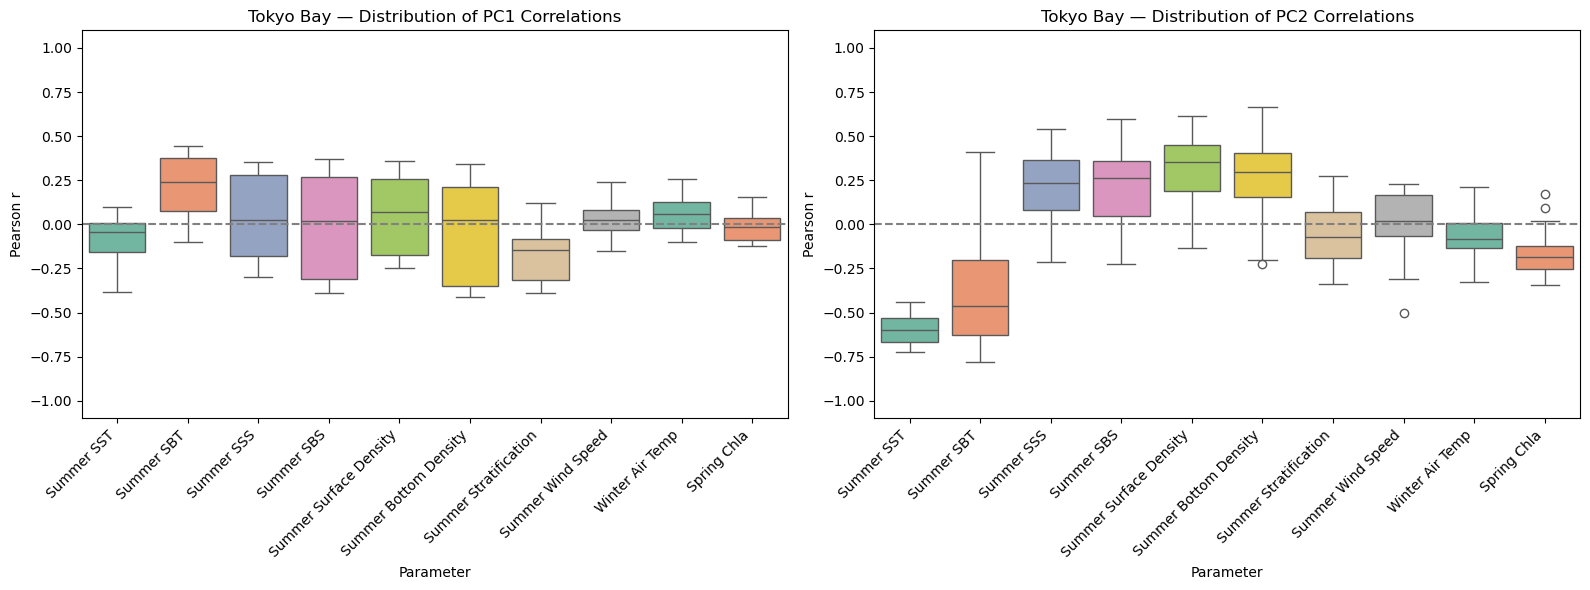

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for ax, corr_df, pc_name in zip(axes, [corr_df_pc1, corr_df_pc2], ['PC1', 'PC2']):
    r_cols = [c for c in corr_df.columns
              if not c.endswith('_pval') and not c.endswith('_n')]
    melted = corr_df[r_cols].melt(var_name='Parameter', value_name='Pearson_r')
    melted['Parameter'] = melted['Parameter'].str.replace('_', ' ')

    sns.boxplot(data=melted, x='Parameter', y='Pearson_r', hue='Parameter',
                ax=ax, palette='Set2', legend=False)
    ax.axhline(0, color='gray', linestyle='--')
    ax.set_title(f'{bay_name} — Distribution of {pc_name} Correlations')
    ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
    ax.set_ylabel('Pearson r')
    ax.set_ylim(-1.1, 1.1)

plt.tight_layout()
plt.show()

### 7b. Diverging bar chart of significant correlations

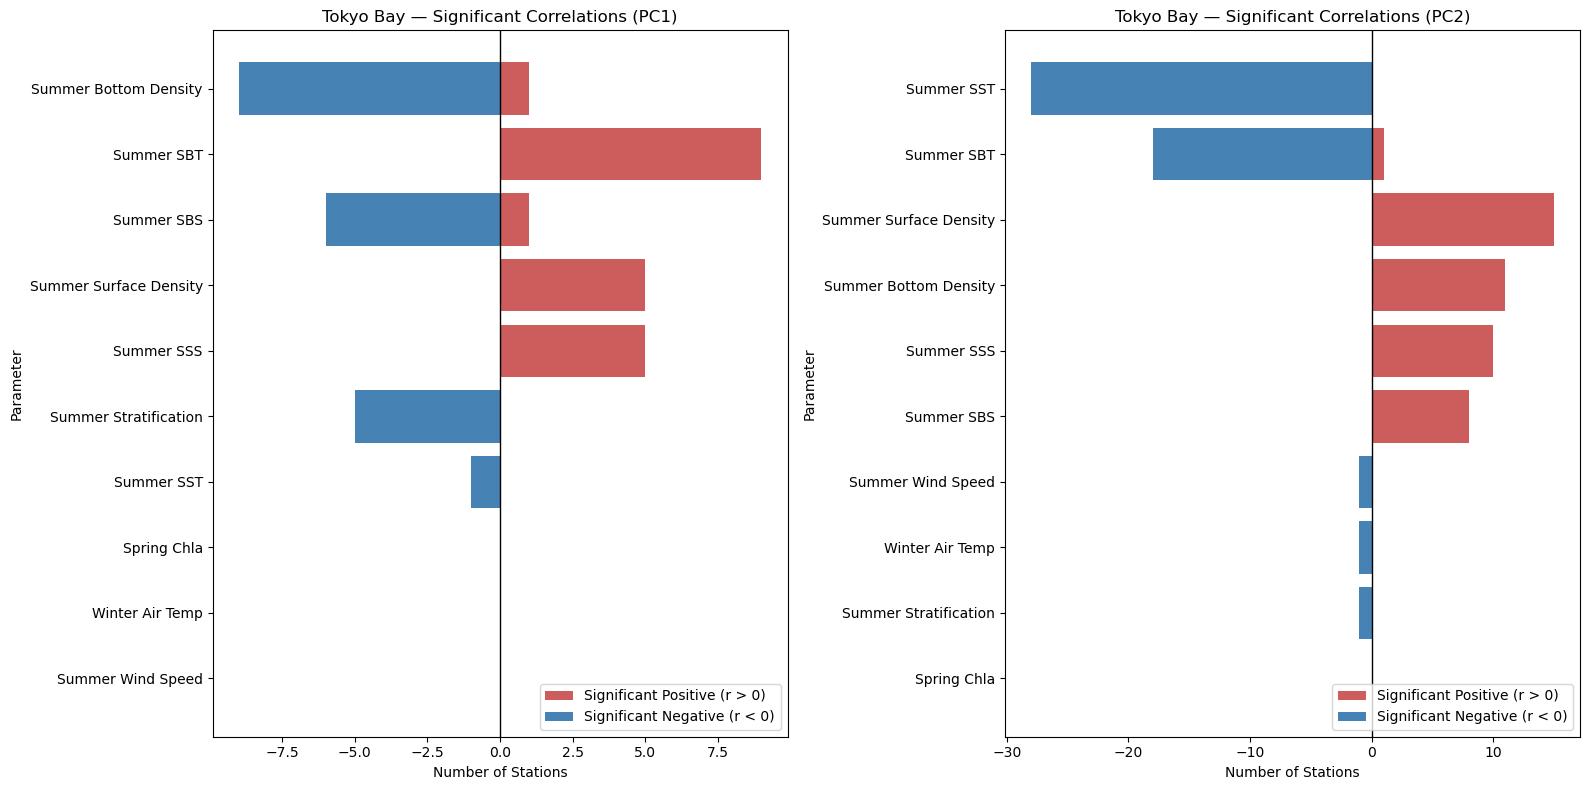

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(16, 8))

for ax, corr_df, pc_name in zip(axes, [corr_df_pc1, corr_df_pc2], ['PC1', 'PC2']):
    r_cols = [c for c in corr_df.columns
              if not c.endswith('_pval') and not c.endswith('_n')]

    counts = []
    for c in r_cols:
        pval_col = f"{c}_pval"
        if pval_col in corr_df.columns:
            sig_pos = ((corr_df[c] > 0) & (corr_df[pval_col] < 0.05)).sum()
            sig_neg = ((corr_df[c] < 0) & (corr_df[pval_col] < 0.05)).sum()
            counts.append({
                'Parameter': c.replace('_', ' '),
                'Positive': sig_pos,
                'Negative': -sig_neg,
                'Total_Significant': sig_pos + sig_neg,
            })

    count_df = pd.DataFrame(counts)
    count_df = count_df.sort_values(by='Total_Significant', ascending=True)

    ax.barh(count_df['Parameter'], count_df['Positive'],
            color='indianred', label='Significant Positive (r > 0)')
    ax.barh(count_df['Parameter'], count_df['Negative'],
            color='steelblue', label='Significant Negative (r < 0)')
    ax.axvline(0, color='black', linewidth=1)
    ax.set_title(f'{bay_name} — Significant Correlations ({pc_name})')
    ax.set_xlabel('Number of Stations')
    ax.set_ylabel('Parameter')
    ax.legend(loc='lower right')

plt.tight_layout()
plt.show()

### 7c. Identify top-2 environmental contributors per PC

In [12]:
def _top_contributors(corr_df, n=2):
    """Return names of the *n* parameters with most significant correlations."""
    r_cols = [c for c in corr_df.columns
              if not c.endswith('_pval') and not c.endswith('_n')]
    totals = {}
    for c in r_cols:
        pval_col = f"{c}_pval"
        if pval_col in corr_df.columns:
            totals[c] = (corr_df[pval_col] < 0.05).sum()
    sorted_params = sorted(totals, key=totals.get, reverse=True)
    return sorted_params[:n]

top_pc1 = _top_contributors(corr_df_pc1, 2)
top_pc2 = _top_contributors(corr_df_pc2, 2)
print(f"Top 2 contributors for PC1: {top_pc1}")
print(f"Top 2 contributors for PC2: {top_pc2}")

Top 2 contributors for PC1: ['Summer_Bottom_Density', 'Summer_SBT']
Top 2 contributors for PC2: ['Summer_SST', 'Summer_SBT']


### 7d. Spatial correlation maps (top-2 contributors per PC)

Mapping top environmental correlators...


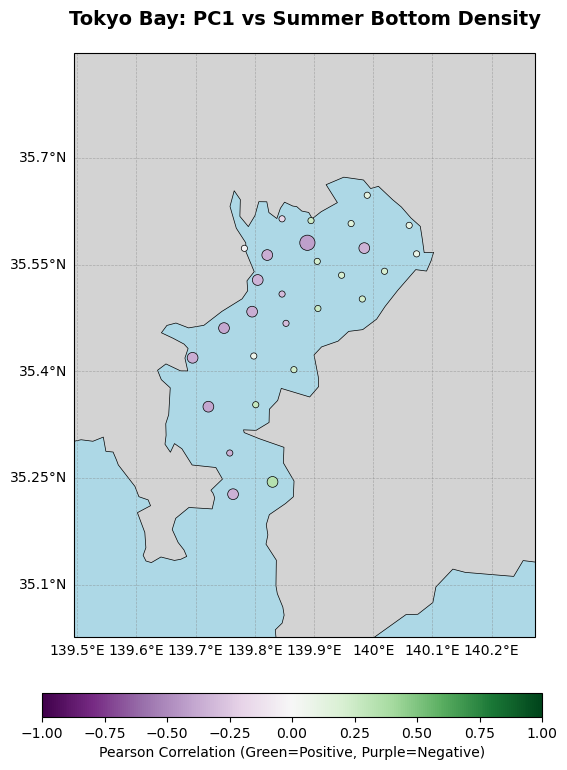

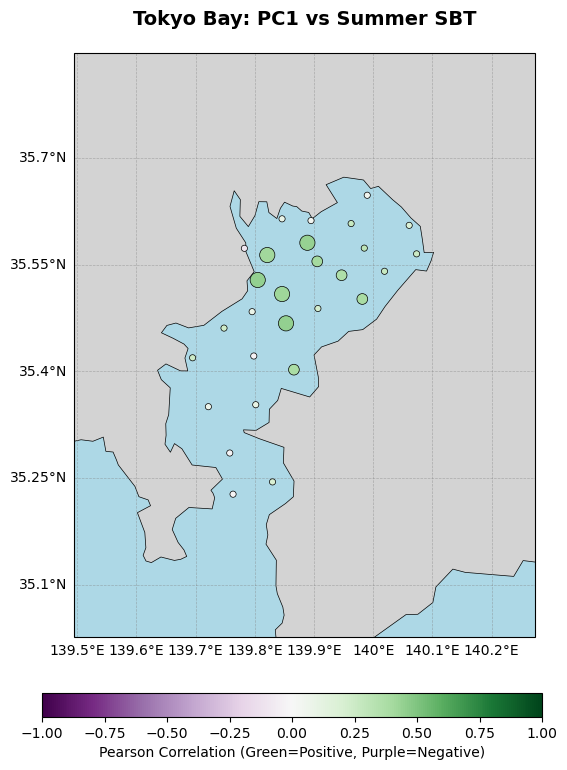

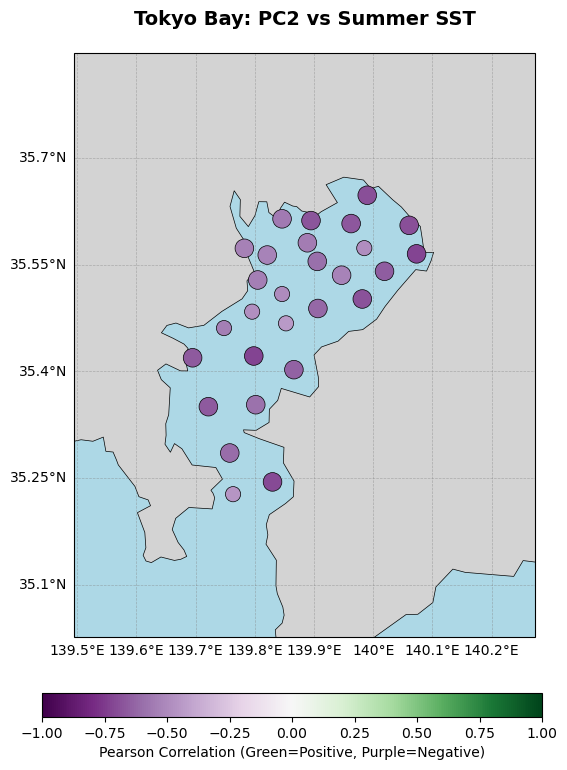

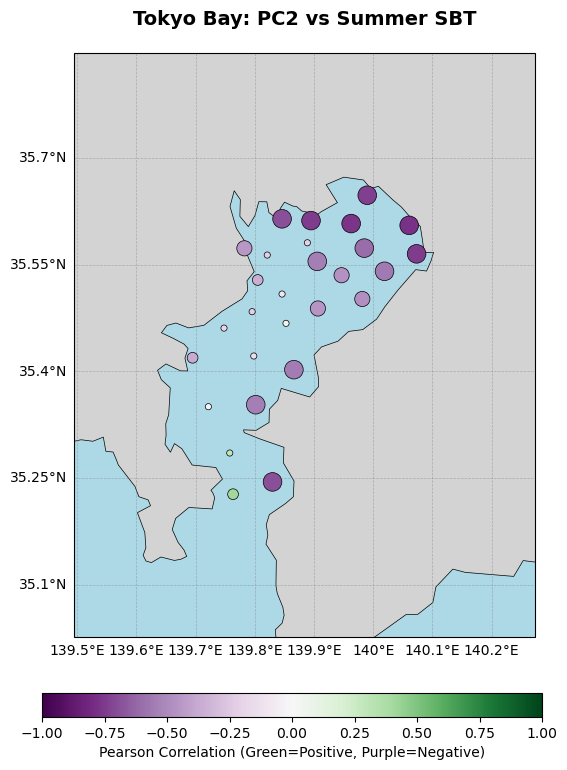


All Tokyo Bay correlation analysis complete.


In [13]:
def plot_env_corr(corr_df, parameter, pc_name, bay_name):
    """Map per-station correlation following 36_plot_env_correlations.py logic."""
    if parameter not in corr_df.columns:
        print(f"Skipping {parameter}: not in correlation DataFrame.")
        return

    p_col = f"{parameter}_pval"
    stn_coords = stations.set_index('zettaicode') if 'zettaicode' in stations.columns else stations

    plot_data = stn_coords.join(corr_df[[parameter, p_col]], how='inner')\
                          .dropna(subset=[parameter, p_col])

    if plot_data.empty:
        print(f"No valid data for {parameter}")
        return

    sizes = [180 if p <= 0.001 else 120 if p <= 0.01
             else 60 if p <= 0.05 else 20
             for p in plot_data[p_col]]

    title = f"{bay_name}: {pc_name} vs {parameter.replace('_', ' ')}"
    fig, ax = create_cartopy_axes(title)

    sc = ax.scatter(plot_data['longitude'], plot_data['latitude'],
                    c=plot_data[parameter], s=sizes,
                    cmap='PRGn', vmin=-1.0, vmax=1.0,
                    edgecolors='k', linewidths=0.5,
                    transform=ccrs.PlateCarree(),
                    zorder=MappingConfig.ZORDER_PREDICTED)

    plt.subplots_adjust(bottom=0.15, wspace=0.05, hspace=0.15)
    cbar_ax = fig.add_axes([0.25, 0.05, 0.5, 0.03])
    cbar = fig.colorbar(sc, cax=cbar_ax, orientation='horizontal')
    cbar.set_label('Pearson Correlation (Green=Positive, Purple=Negative)')
    plt.show()


print("Mapping top environmental correlators...")
for param in top_pc1:
    plot_env_corr(corr_df_pc1, param, 'PC1', bay_name)

for param in top_pc2:
    plot_env_corr(corr_df_pc2, param, 'PC2', bay_name)

print(f"\nAll {bay_name} correlation analysis complete.")